# Task 5 — Tail Family & Reference Follow-up

Unsupervised: ไม่มี is_anomaly จึงไม่รายงาน offline F₃/precision/recall ผลด้านล่างอธิบาย detector และความไวของ ranking

ทำซ้ำ scored v20 → EDA → fixed score alternatives → full-reference primary/control → saved predictions. ค่าเริ่มต้นอ่านผลที่เสร็จแล้ว ไม่เริ่ม train เมื่อ Run All


## 1. Setup


In [1]:
from pathlib import Path
import sys, os, json
import pandas as pd
import numpy as np
from IPython.display import display, Image
ROOT = next(candidate for base in (Path.cwd(), *Path.cwd().parents) for candidate in (base, base / "CPE342-Kaggle") if (candidate / "Task5/models/tail_family_followup.py").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "Task5/cache/matplotlib"))
from Task5.models import tail_family_followup as experiment
from Task5.models import tail_full_reference as final
from Task5.models import report_tail_followup as report
OUT, FINAL = experiment.OUT, final.OUT
print("Audit:", OUT)
print("Final:", FINAL)


Audit: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task5/models/results/tail_family_followup_v1
Final: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task5/models/results/tail_full_reference_v1


## 2. Run or Reload

คง source/config/data เดิมเพื่อ reuse caches; เปลี่ยนการทดลองให้ใช้ output directory ใหม่


In [2]:
RUN_MODELS = False
if RUN_MODELS:
    experiment.run()
    final.run()
    report.generate()
else:
    print("Read existing results; no model training started")
card = json.loads((FINAL / "model_card.json").read_text())
proof = json.loads((FINAL / "verification.json").read_text())
display(pd.Series(proof).to_frame("verified"))


Read existing results; no model training started


,verified
raw_rows,25889
raw_features,122
engineered_features,213
all_original_feature_values_match_source,True
baseline_decisions_exactly_reproduced,25889
diagnostic_models_reloaded_all_rows,5
operational_models_reloaded_all_rows,2
primary_family_cap_verified_all_rows,True
cross_reference_rows_recomputed,25889
anomaly_labels_available,False


## 3. Data Quality and Undocumented Codes


In [3]:
quality = pd.read_csv(OUT / "raw_quality.csv")
display(quality.sort_values("missing_count", ascending=False).head(12))
display(pd.read_csv(OUT / "semantic_range_checks.csv"))
display(pd.read_csv(OUT / "minus_one_code_audit.csv"))


,feature,missing_count,missing_pct,min,max,unique
118,password_changed,1363,5.264784,0.000000,1.000000,2
109,communication_frequency_2,1353,5.226158,0.000093,1.556518,24536
89,purchase_amount_std_2,1326,5.121866,0.001163,258.989985,24563
28,session_duration_mean_1,1324,5.114141,24.335186,214.280348,24565
5,login_lon_1,1319,5.094828,-180.564971,181.823919,24570
73,reaction_time_std_2,1319,5.094828,16.132434,71.783345,24570
25,login_time_variance_2,1314,5.075515,0.100212,9.572375,24575
97,currency_transfers_2,1312,5.067789,0.000768,12.915613,24577
79,performance_stability_4,1312,5.067789,0.599465,0.996096,24577
23,ip_hash_entropy_4,1311,5.063927,0.000498,0.799977,24578


,check,rows,cells
0,negative_counts,10186,13605.0
1,consistency_outside_0_1,179,180.0
2,entropy_outside_0_1,0,0.0
3,accuracy_outside_0_100,0,0.0
4,invalid_geo_pairs_masked,218,NaN


,family,minus_one_cells,rows_any_minus_one,other_negative_cells,nan_cells,interpretation
0,refund_count,8185,6866,0,5037,Undocumented -1 code; may be sentinel or gener...
1,guild_changes,5420,4529,0,5024,Undocumented -1 code; may be sentinel or gener...


## 4. Temporal Persistence and Cohort Trends


,family,median_period_spearman,rows_lt3_observed,negative_cells
3,ip_hash_entropy,0.024316,350,0
2,device_count,0.425884,338,0
21,refund_count,0.438484,365,8185
26,guild_changes,0.655196,317,5420
9,play_pattern_consistency,0.761410,335,0
17,performance_stability,0.794722,364,0
16,reaction_time_std,0.837682,338,0
10,activity_level,0.839904,348,0
14,accuracy_std,0.858376,370,0
1,location_changes,0.868161,311,0


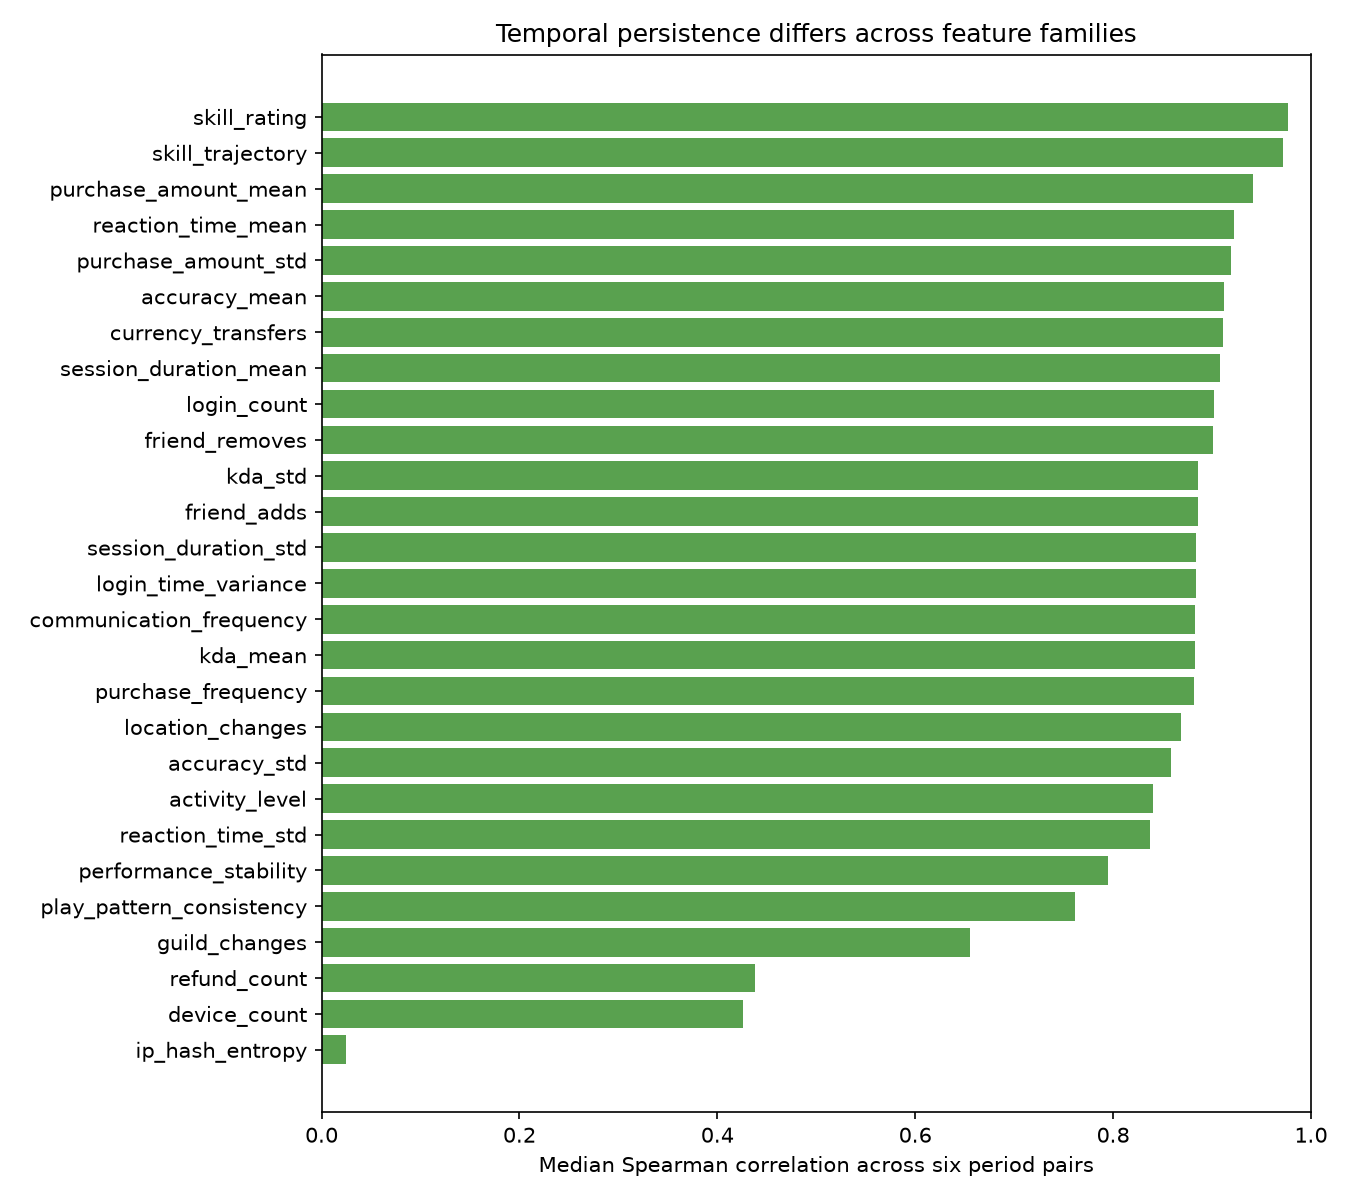

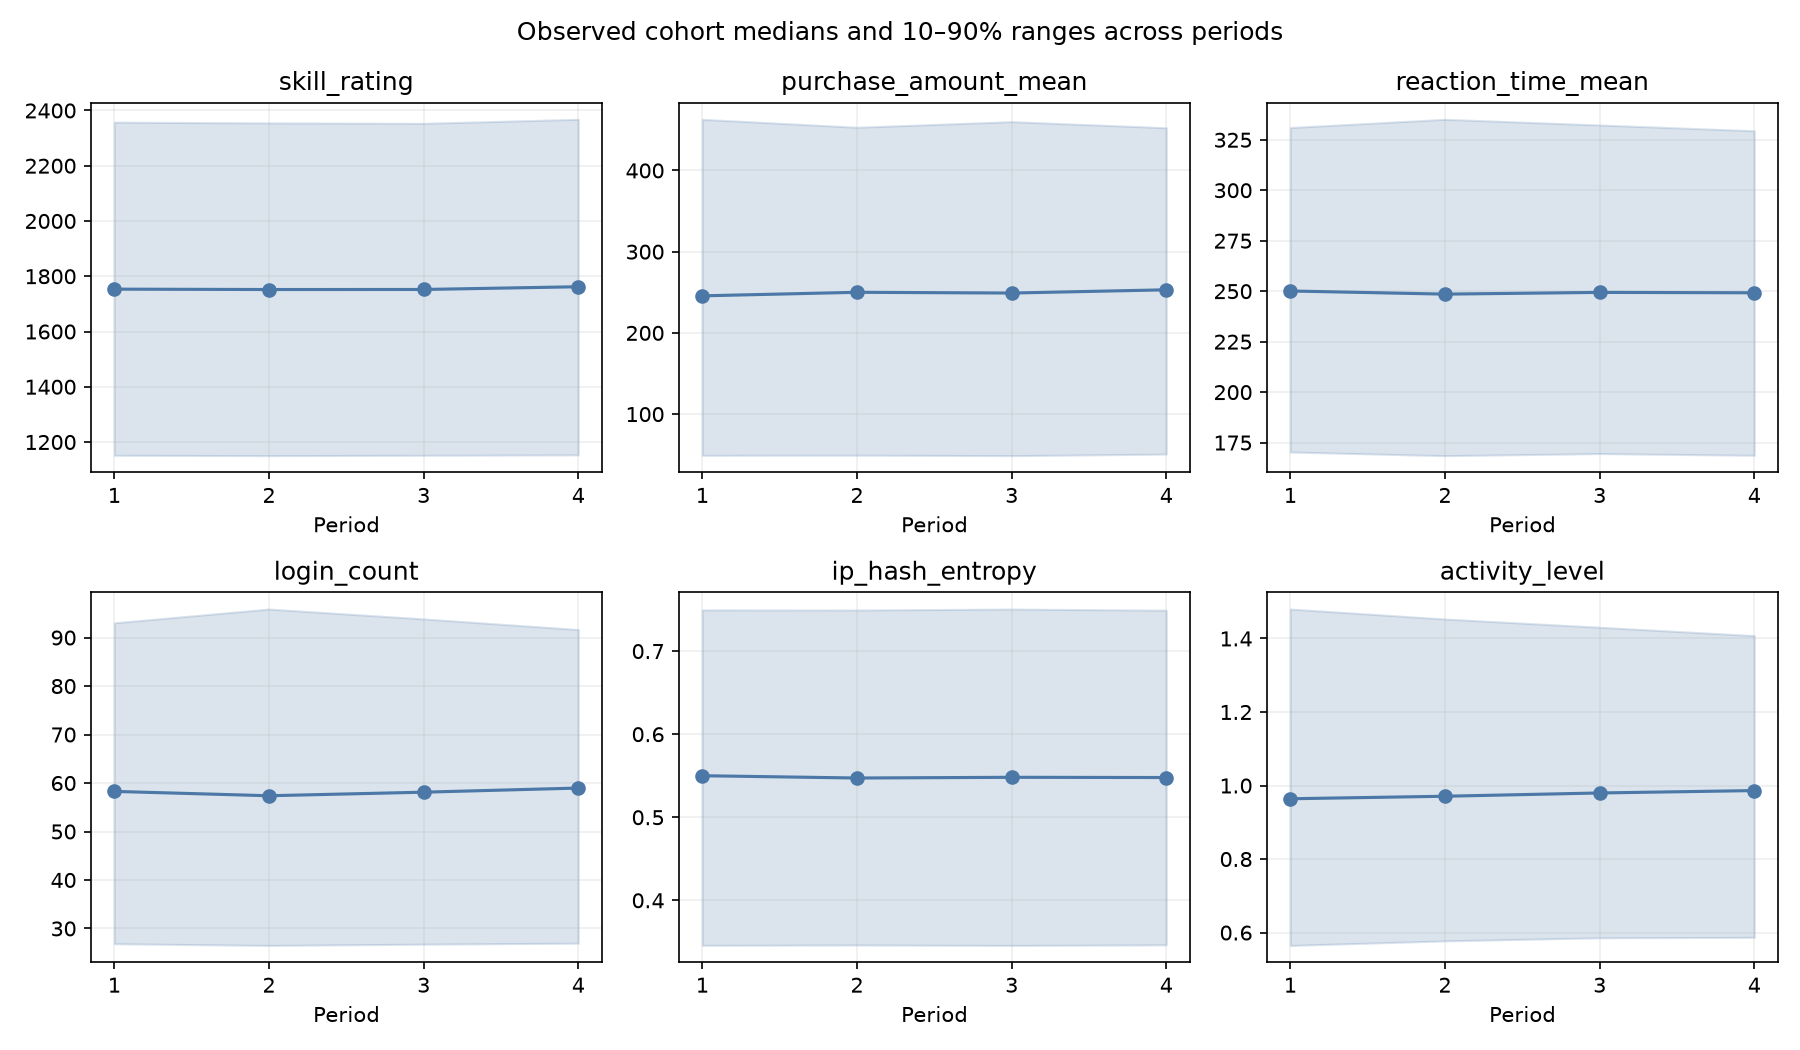

In [4]:
period_audit = pd.read_csv(OUT / "period_family_audit.csv")
display(period_audit.sort_values("median_period_spearman"))
display(Image(filename=str(OUT / "figures/temporal_persistence.png")))
display(Image(filename=str(OUT / "figures/period_profiles.png")))


## 5. Decompose the Scored Tail


,group,rows,median_distinct_families,fraction_3plus_slots_one_family,median_largest_family_share,fraction_half_score_one_family
0,all,25889,4.0,0.786898,0.410690,0.306617
1,baseline_alert,6531,4.0,0.915939,0.504770,0.512173
2,baseline_nonalert,19358,5.0,0.743362,0.392581,0.237266


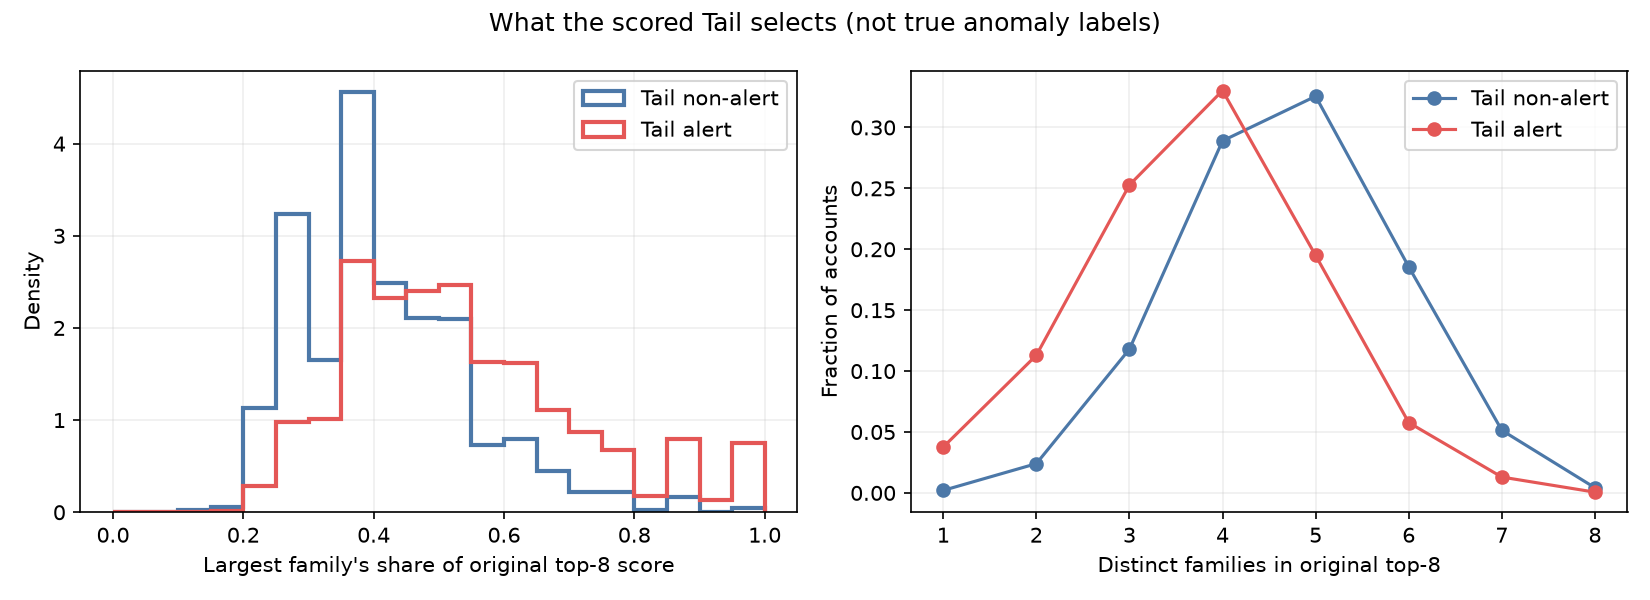

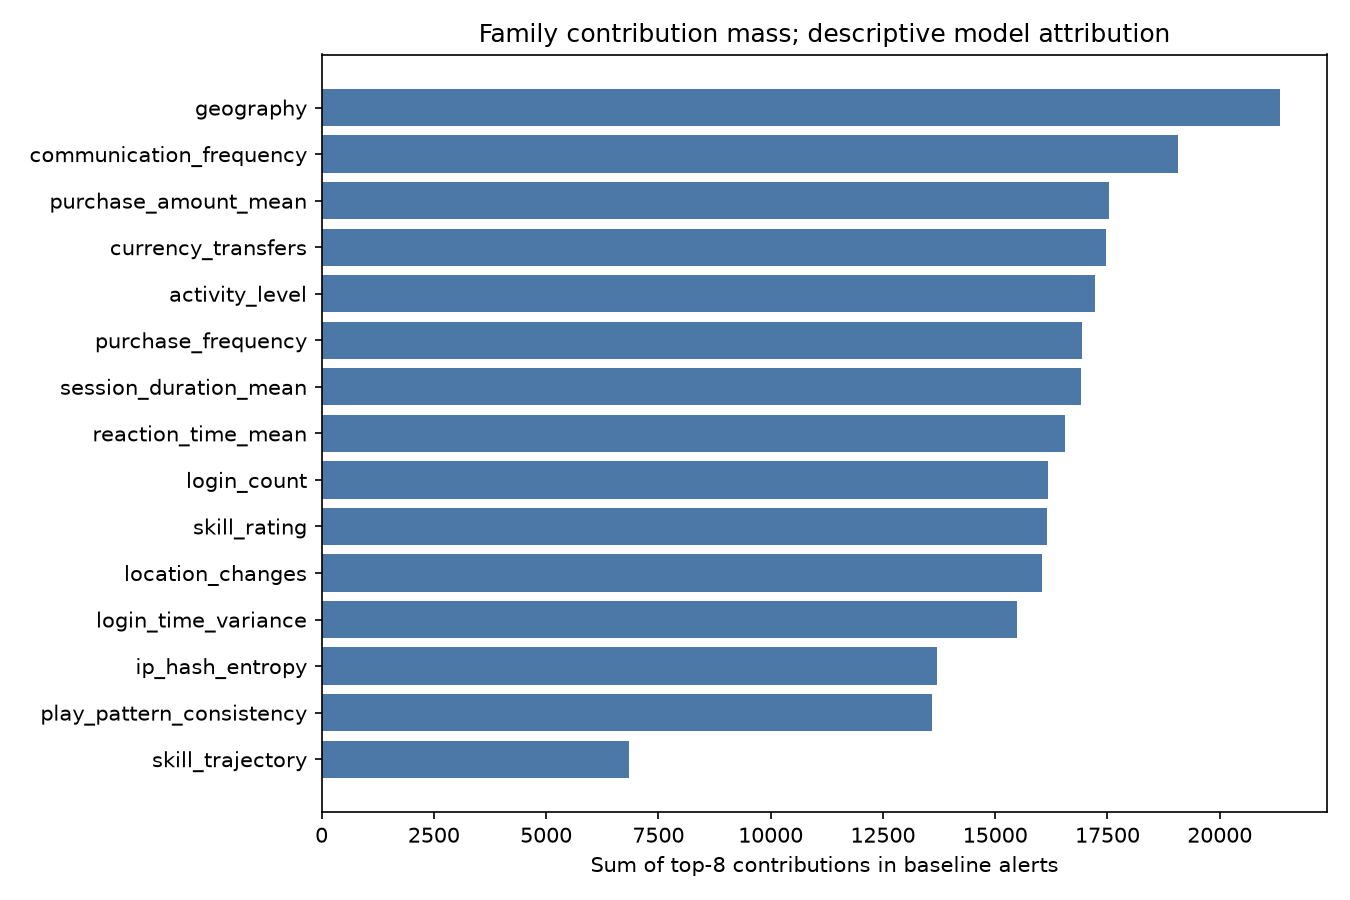

In [5]:
display(pd.read_csv(OUT / "family_concentration_summary.csv"))
display(Image(filename=str(OUT / "figures/family_concentration.png")))
display(Image(filename=str(OUT / "figures/family_mass.png")))


In [6]:
mapping = pd.read_csv(OUT / "feature_family_map.csv")
display(mapping.groupby("family").size().rename("feature_count").sort_values(ascending=False).to_frame())
contributions = pd.read_parquet(OUT / "baseline_top8_contributions.parquet")
geo = contributions.loc[contributions.baseline_alert.eq(1) & contributions.family.eq("geography")]
absolute = geo.feature.str.startswith(("login_lat_", "login_lon_"))
display(pd.Series({"geography_slots": len(geo), "absolute_coordinate_slots": int(absolute.sum()), "absolute_coordinate_share_of_geography_contribution": geo.loc[absolute, "contribution"].sum()/geo.contribution.sum()}).to_frame("value"))


,feature_count
family,
geography,13
location_changes,10
skill_rating,10
login_time_variance,10
login_count,10
session_duration_mean,10
play_pattern_consistency,10
purchase_amount_mean,10
ip_hash_entropy,10


,value
geography_slots,3726.000000
absolute_coordinate_slots,2655.000000
absolute_coordinate_share_of_geography_contribution,0.710455


## 6. Fixed Detector Alternatives

Jaccard/Spearman วัดการเปลี่ยนชุดและ repeatability ไม่ใช่ F₃ ไม่มีการจัดอันดับคุณภาพโมเดลจากค่าเหล่านี้


In [7]:
display(pd.read_csv(OUT / "model_diagnostics.csv").round(5))
display(pd.read_csv(OUT / "missing_geo_score_correlations.csv", index_col=0).round(4))
display(pd.read_csv(OUT / "structural_sensitivity.csv").round(5))


,model,alerts,shared_alerts,added_alerts,removed_alerts,alert_jaccard_vs_baseline,score_spearman_vs_baseline,disjoint_reference_holdout_jaccard,disjoint_reference_holdout_spearman,seconds,role
0,tail_original,6531,6531,0,0,1.00000,1.00000,0.91022,0.99525,1.96164,diagnostic
1,tail_family_cap2,6531,5655,876,876,0.76347,0.96573,0.89934,0.99535,2.12586,primary
2,tail_family_cap3,6531,6110,421,421,0.87888,0.98987,0.91755,0.99527,2.09749,control
3,family_calibrated_top4,6531,4826,1705,1705,0.58596,0.83556,0.87617,0.98661,2.56476,diagnostic
4,copula_joint,6531,3174,3357,3357,0.32100,0.49177,0.92123,0.99499,3.21073,diagnostic


,missing_count,masked_geo,security_flag_count,baseline_score,candidate_score
missing_count,1.0000,0.1553,0.0055,0.0316,0.0359
masked_geo,0.1553,1.0000,0.0207,0.0343,0.0336
security_flag_count,0.0055,0.0207,1.0000,0.0485,0.0545
baseline_score,0.0316,0.0343,0.0485,1.0000,0.9657
candidate_score,0.0359,0.0336,0.0545,0.9657,1.0000


,perturbation,model,rank_spearman,same_budget_alert_jaccard,median_score_delta
0,reverse_periods,tail_original,0.62855,0.41809,7.87985
1,reverse_periods,tail_family_cap2,0.58873,0.38987,8.36904
2,reverse_periods,tail_family_cap3,0.61108,0.40180,8.11448
3,reverse_periods,copula_joint,0.88914,0.66522,29.33723
4,constant_period1,tail_original,NaN,0.14178,39.39515
5,constant_period1,tail_family_cap2,NaN,0.14148,40.43799
6,constant_period1,tail_family_cap3,NaN,0.14288,39.69911
7,constant_period1,copula_joint,0.13811,0.18843,246.39828


## 7. Full Reference and Cross-Scoring Audit

Cross-reference folds ให้คะแนนบัญชีที่อยู่นอก reference เพื่อวัด sensitivity เท่านั้น ไม่ใช่ OOF ที่วัด accuracy เพราะไม่มี labels


,membership,rows,original_alert_rate,original_mean_score,full_cap2_alert_rate
0,in_original_reference,12000,0.24467,36.54887,0.24750
1,out_of_original_reference,13889,0.25884,36.82079,0.25639


,model,reference_rows,alerts,added_vs_scored,removed_vs_scored,jaccard_vs_scored,spearman_vs_scored,operational_threshold,seconds
0,full_original_tail,25889,6531,159,159,0.95247,0.99877,39.74829,4.07700
1,full_family_cap2,25889,6531,854,854,0.76872,0.96458,38.15602,4.28947


,value
spearman_vs_primary,0.999685
alert_jaccard_vs_primary,0.975499
note,Unlabeled cross-scoring sensitivity only; not ...


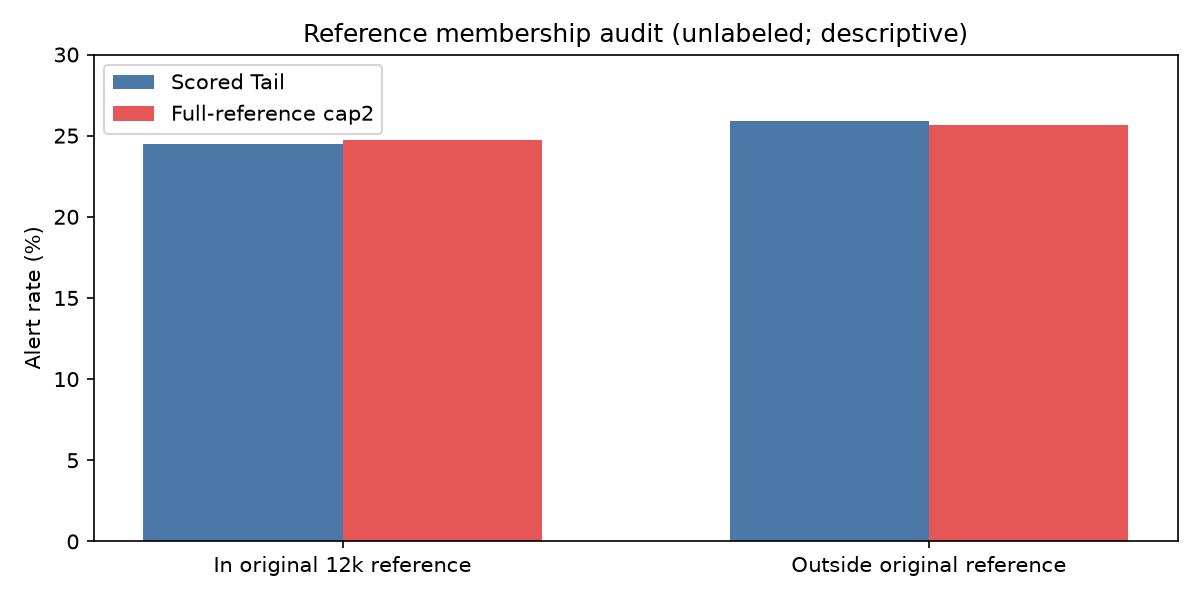

In [8]:
display(pd.read_csv(FINAL / "reference_membership_audit.csv").round(5))
display(pd.read_csv(FINAL / "model_diagnostics.csv").round(5))
display(pd.Series(json.loads((FINAL / "cross_reference_diagnostic.json").read_text())).to_frame("value"))
display(Image(filename=str(FINAL / "figures/reference_membership.png")))


## 8. Which Accounts Change?


,group,rows,missing_feature_count,security_flag_count,login_move_max_km,login_count_mean4,skill_rating_std4,purchase_amount_mean_max_step
0,shared_alert,5677,6.0,0.0,117.1955,60.2218,46.7950,54.9503
1,added_alert,854,6.0,0.0,121.0581,61.0140,45.5656,54.9612
2,removed_alert,854,6.0,0.0,111.8535,60.2309,45.4635,45.4169
3,shared_nonalert,18504,6.0,0.0,116.0382,58.5675,43.6626,48.6337


,group,rows,median_score_reduction
0,Added,854,0.15475
1,Removed,854,4.55202
2,Shared alerts,5677,1.57011


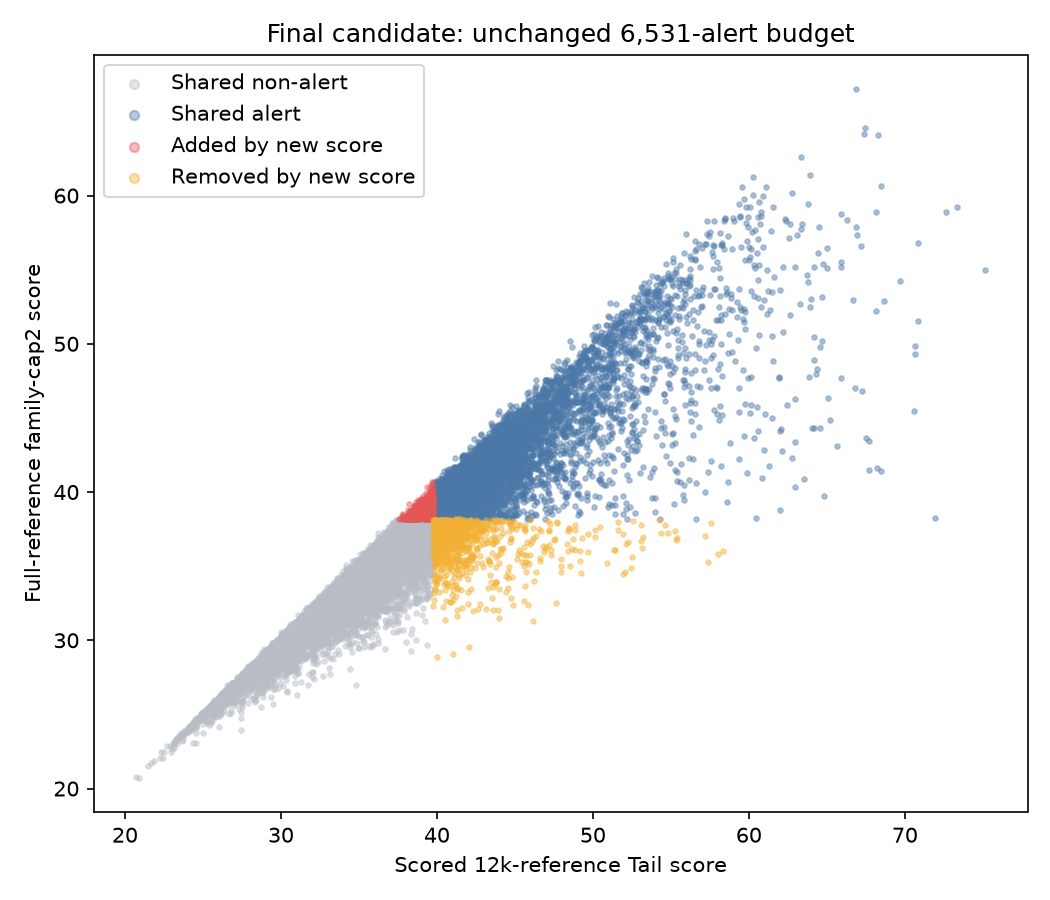

In [9]:
profiles = pd.read_csv(FINAL / "primary_discordance_profile_medians.csv")
review = ["group", "rows", "missing_feature_count", "security_flag_count", "login_move_max_km", "login_count_mean4", "skill_rating_std4", "purchase_amount_mean_max_step"]
display(profiles[review].round(4))
display(pd.read_csv(FINAL / "cap_penalty_by_discordance.csv").round(5))
display(Image(filename=str(FINAL / "figures/final_score_disagreement.png")))


## 9. Saved Models and Predictions

Primary = full-reference Family-cap2; control = original top-8 Tail with full reference. ทั้งคู่คง 6,531 alerts และยังไม่ส่ง Kaggle


In [10]:
print("Primary:", card["primary"])
print("Control:", card["control"])
print("Operational models:", card["operational_models"])
print("Scored source:", card["source_submission"])
for name in [final.PRIMARY, final.CONTROL]:
    pred = pd.read_parquet(FINAL / f"{name}_predictions.parquet")
    assert len(pred) == 25889 and pred.player_id.is_unique and pred.id.is_unique
    assert pred.task5.isin([0,1]).all() and pred.task5.sum() == 6531
    print(name, "alerts:", int(pred.task5.sum()), "file:", FINAL / f"{name}_predictions.csv")
    display(pred.head())


Primary: full_family_cap2
Control: full_original_tail
Operational models: {'full_original_tail': 'Task5/models/results/tail_full_reference_v1/full_original_tail_operational.joblib', 'full_family_cap2': 'Task5/models/results/tail_full_reference_v1/full_family_cap2_operational.joblib'}
Scored source: submission/kaggle_t12345_t1_slow800_bagging_v4_t3_conditional_quantile_v1_t4_resnet18_cosine18_tta_v1_t5_tail_engineered_v20.csv
full_family_cap2 alerts: 6531 file: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task5/models/results/tail_full_reference_v1/full_family_cap2_predictions.csv
full_original_tail alerts: 6531 file: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task5/models/results/tail_full_reference_v1/full_original_tail_predictions.csv


,test_row_index,player_id,id,task5,anomaly_score
0,0,P024743,ANS00001,1,40.367020
1,1,P005319,ANS00002,0,32.770650
2,2,P014970,ANS00003,1,51.083841
3,3,P003275,ANS00004,1,41.287843
4,4,P009022,ANS00005,0,32.438123


,test_row_index,player_id,id,task5,anomaly_score
0,0,P024743,ANS00001,1,40.902222
1,1,P005319,ANS00002,0,32.770650
2,2,P014970,ANS00003,1,51.166362
3,3,P003275,ANS00004,1,41.994715
4,4,P009022,ANS00005,0,32.438123
